# Cricket Players Analysis Project


### 1. Players Data Setup


In [1]:
import numpy as np
import os

players = np.array(["Babar", "Rizwan", "Fakhar", "Iftikhar", "Shadab"])

# Runs scored in 5 matches
runs = np.array([
    [54, 78, 23, 90, 65],  # Babar
    [45, 60, 52, 38, 85],  # Rizwan
    [80, 12, 105, 8, 42],  # Fakhar
    [25, 30, 15, 45, 20],  # Iftikhar
    [32, 18, 40, 55, 10]   # Shadab
])

# Balls faced in 5 matches
balls = np.array([
    [42, 58, 20, 65, 50],
    [38, 48, 40, 32, 60],
    [50, 15, 60, 10, 30],
    [18, 22, 12, 28, 15],
    [20, 14, 25, 35, 12]
])

print("Players:", players)
print("\nRuns Matrix:\n", runs)


Players: ['Babar' 'Rizwan' 'Fakhar' 'Iftikhar' 'Shadab']

Runs Matrix:
 [[ 54  78  23  90  65]
 [ 45  60  52  38  85]
 [ 80  12 105   8  42]
 [ 25  30  15  45  20]
 [ 32  18  40  55  10]]


### 2. Total Runs & Average


In [2]:
total_runs = np.sum(runs, axis=1)
avg_runs = np.mean(runs, axis=1)

for i in range(len(players)):
    print(f"{players[i]}: Total = {total_runs[i]}, Average = {avg_runs[i]:.1f}")


Babar: Total = 310, Average = 62.0
Rizwan: Total = 280, Average = 56.0
Fakhar: Total = 247, Average = 49.4
Iftikhar: Total = 135, Average = 27.0
Shadab: Total = 155, Average = 31.0


### 3. Top Scorer & Highest Innings


In [3]:
# Top scorer index
top_idx = np.argmax(total_runs)
print(f"Top Scorer: {players[top_idx]} ({total_runs[top_idx]} runs)")

# Highest score in single match
max_score = np.max(runs)
p_idx, m_idx = np.where(runs == max_score)
print(f"Highest Innings: {max_score} by {players[p_idx[0]]} in Match {m_idx[0] + 1}")


Top Scorer: Babar (310 runs)
Highest Innings: 105 by Fakhar in Match 3


### 4. Strike Rate


In [4]:
total_balls = np.sum(balls, axis=1)
strike_rate = (total_runs / total_balls) * 100

for i in range(len(players)):
    print(f"{players[i]}: Strike Rate = {strike_rate[i]:.2f}")


Babar: Strike Rate = 131.91
Rizwan: Strike Rate = 128.44
Fakhar: Strike Rate = 149.70
Iftikhar: Strike Rate = 142.11
Shadab: Strike Rate = 146.23


### 5. Match-wise Team Totals


In [5]:
team_totals = np.sum(runs, axis=0)

for m in range(5):
    print(f"Match {m + 1} Total: {team_totals[m]} runs")


Match 1 Total: 236 runs
Match 2 Total: 198 runs
Match 3 Total: 235 runs
Match 4 Total: 236 runs
Match 5 Total: 222 runs


### 6. Fifties & Categories


In [6]:
# Count 50+ scores
fifties = np.sum(runs >= 50, axis=1)

# Category based on average runs
category = np.where(avg_runs >= 50, "Star Player", "Regular Player")

for i in range(len(players)):
    print(f"{players[i]:<10} | Fifties: {fifties[i]} | Role: {category[i]}")


Babar      | Fifties: 4 | Role: Star Player
Rizwan     | Fifties: 3 | Role: Star Player
Fakhar     | Fifties: 2 | Role: Regular Player
Iftikhar   | Fifties: 0 | Role: Regular Player
Shadab     | Fifties: 1 | Role: Regular Player


### 7. Summary Table & Save to CSV


In [7]:
player_ids = np.array([1, 2, 3, 4, 5])

summary = np.column_stack([
    player_ids,
    total_runs,
    avg_runs.round(1),
    total_balls,
    strike_rate.round(2),
    fifties
])

print("ID | Runs | Avg | Balls | SR | 50s")
print(summary)

# Save CSV
csv_dir = "../csv" if os.path.exists("../csv") else "csv"
os.makedirs(csv_dir, exist_ok=True)
csv_file = os.path.join(csv_dir, "players_summary.csv")

np.savetxt(
    csv_file,
    summary,
    delimiter=",",
    header="PlayerID,TotalRuns,AverageRuns,TotalBalls,StrikeRate,Fifties",
    fmt=["%d", "%d", "%.1f", "%d", "%.2f", "%d"],
    comments=""
)
print(f"\nSaved to {csv_file}")


ID | Runs | Avg | Balls | SR | 50s
[[  1.   310.    62.   235.   131.91   4.  ]
 [  2.   280.    56.   218.   128.44   3.  ]
 [  3.   247.    49.4  165.   149.7    2.  ]
 [  4.   135.    27.    95.   142.11   0.  ]
 [  5.   155.    31.   106.   146.23   1.  ]]

Saved to csv\players_summary.csv


### 8. Data Visualization (Matplotlib & Seaborn)


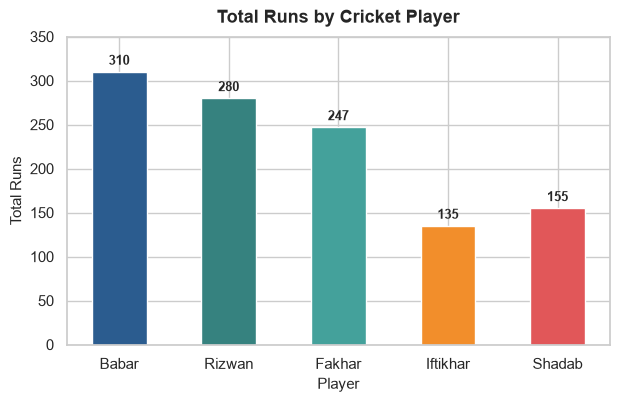

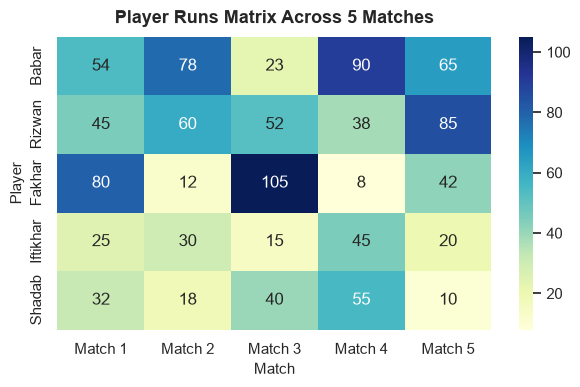

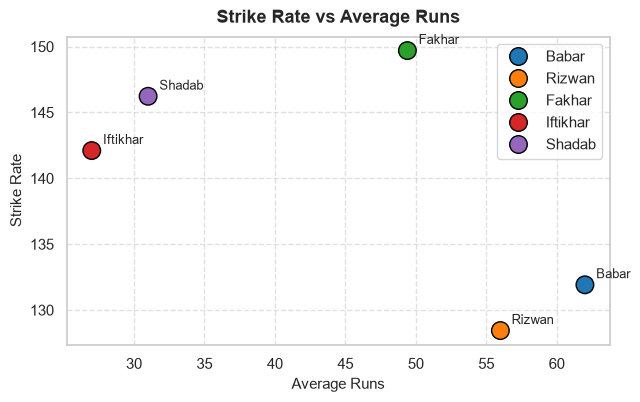

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Total Runs Bar Chart (Matplotlib)
plt.figure(figsize=(7, 4))
colors = ['#2b5c8f', '#36827f', '#44a19b', '#f28e2b', '#e15759']
bars = plt.bar(players, total_runs, color=colors, width=0.5)
plt.title("Total Runs by Cricket Player", fontsize=13, fontweight='bold', pad=10)
plt.xlabel("Player", fontsize=11)
plt.ylabel("Total Runs", fontsize=11)
plt.ylim(0, max(total_runs) + 40)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 5, f"{int(yval)}", ha='center', va='bottom', fontsize=9, fontweight='bold')
plt.show()

# 2. Match-by-Match Runs Heatmap (Seaborn)
plt.figure(figsize=(7, 3.8))
match_labels = [f"Match {i+1}" for i in range(5)]
sns.heatmap(runs, annot=True, fmt="d", cmap="YlGnBu", xticklabels=match_labels, yticklabels=players)
plt.title("Player Runs Matrix Across 5 Matches", fontsize=13, fontweight='bold', pad=10)
plt.xlabel("Match", fontsize=11)
plt.ylabel("Player", fontsize=11)
plt.show()

# 3. Strike Rate vs Average Runs (Seaborn Scatterplot)
plt.figure(figsize=(7, 4))
sns.scatterplot(x=avg_runs, y=strike_rate, hue=players, s=160, palette="tab10", edgecolor="black")
for i, txt in enumerate(players):
    plt.annotate(txt, (avg_runs[i] + 0.8, strike_rate[i] + 0.5), fontsize=9)
plt.title("Strike Rate vs Average Runs", fontsize=13, fontweight='bold', pad=10)
plt.xlabel("Average Runs", fontsize=11)
plt.ylabel("Strike Rate", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()
